In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('gurgaon_properties_13k_missing_value_imputation.csv')

In [4]:
df.shape

(13189, 19)

In [5]:
df.head()

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,facing,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,house,independent,sector 23,5.50,21825.0,8,8,2,3.0,East,Moderately Old,2520.0,1,1,0,1,0,1,104
1,flat,emaar palm gardens,sector 83,1.80,9473.0,3,3,3,6.0,South,Relatively New,1553.0,0,1,0,0,0,1,146
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,3,3,1,6.0,North-West,Relatively New,2574.0,0,0,0,0,0,1,107
3,flat,ss the leaf,sector 85,1.04,5973.0,2,3,3+,4.0,West,Relatively New,1567.0,0,0,1,0,0,0,149
4,flat,ramprastha the edge towers,sector 37d,0.80,8888.0,2,2,3,10.0,South-East,Relatively New,1310.0,0,0,0,0,1,0,220


In [6]:
train_df = df.drop(columns=['society', 'price_per_sqft']).copy()

In [7]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,facing,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,house,sector 23,5.50,8,8,2,3.0,East,Moderately Old,2520.0,1,1,0,1,0,1,104
1,flat,sector 83,1.80,3,3,3,6.0,South,Relatively New,1553.0,0,1,0,0,0,1,146
2,flat,sector 83,1.30,3,3,1,6.0,North-West,Relatively New,2574.0,0,0,0,0,0,1,107
3,flat,sector 85,1.04,2,3,3+,4.0,West,Relatively New,1567.0,0,0,1,0,0,0,149
4,flat,sector 37d,0.80,2,2,3,10.0,South-East,Relatively New,1310.0,0,0,0,0,1,0,220


## Feature Engineering: `luxury_score`

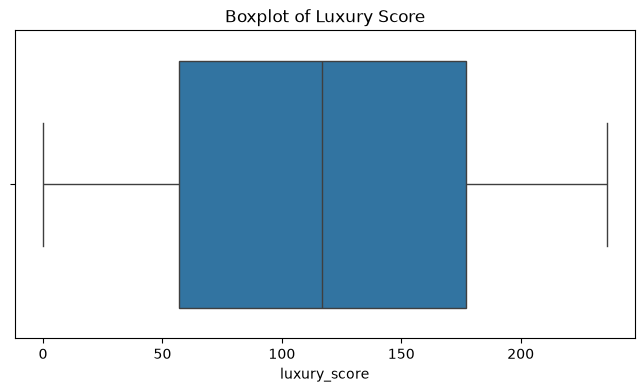

In [8]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['luxury_score'])
plt.title('Boxplot of Luxury Score')
plt.show()

In [9]:
def categorize_luxury(score):
    if 0 <= score < 50:
        return "Low"
    elif 50 <= score < 150:
        return "Medium"
    elif score >= 150:
        return "High"
    else:
        return None

In [10]:
train_df['luxury_category'] = train_df['luxury_score'].apply(categorize_luxury)

In [11]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,facing,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score,luxury_category
0,house,sector 23,5.50,8,8,2,3.0,East,Moderately Old,2520.0,1,1,0,1,0,1,104,Medium
1,flat,sector 83,1.80,3,3,3,6.0,South,Relatively New,1553.0,0,1,0,0,0,1,146,Medium
2,flat,sector 83,1.30,3,3,1,6.0,North-West,Relatively New,2574.0,0,0,0,0,0,1,107,Medium
3,flat,sector 85,1.04,2,3,3+,4.0,West,Relatively New,1567.0,0,0,1,0,0,0,149,Medium
4,flat,sector 37d,0.80,2,2,3,10.0,South-East,Relatively New,1310.0,0,0,0,0,1,0,220,High


## Feature Engineering: `floorNum`

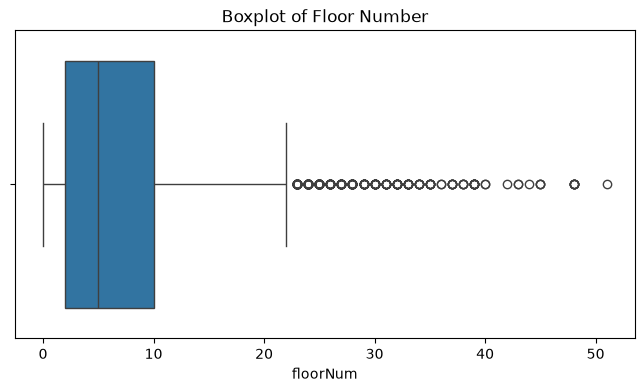

In [12]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['floorNum'])
plt.title('Boxplot of Floor Number')
plt.show()

In [13]:
def categorize_floor(floor):
    if 0 <= floor <= 2:
        return "Low Floor"
    elif 3 <= floor <= 10:
        return "Mid Floor"
    elif 11 <= floor <= 51:
        return "High Floor"
    else:
        return None

In [14]:
train_df['floor_category'] = train_df['floorNum'].apply(categorize_floor)

In [15]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,facing,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score,luxury_category,floor_category
0,house,sector 23,5.50,8,8,2,3.0,East,Moderately Old,2520.0,1,1,0,1,0,1,104,Medium,Mid Floor
1,flat,sector 83,1.80,3,3,3,6.0,South,Relatively New,1553.0,0,1,0,0,0,1,146,Medium,Mid Floor
2,flat,sector 83,1.30,3,3,1,6.0,North-West,Relatively New,2574.0,0,0,0,0,0,1,107,Medium,Mid Floor
3,flat,sector 85,1.04,2,3,3+,4.0,West,Relatively New,1567.0,0,0,1,0,0,0,149,Medium,Mid Floor
4,flat,sector 37d,0.80,2,2,3,10.0,South-East,Relatively New,1310.0,0,0,0,0,1,0,220,High,Mid Floor


In [16]:
train_df.drop(columns=['floorNum', 'luxury_score'], inplace=True)

In [17]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,facing,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_category,floor_category
0,house,sector 23,5.50,8,8,2,East,Moderately Old,2520.0,1,1,0,1,0,1,Medium,Mid Floor
1,flat,sector 83,1.80,3,3,3,South,Relatively New,1553.0,0,1,0,0,0,1,Medium,Mid Floor
2,flat,sector 83,1.30,3,3,1,North-West,Relatively New,2574.0,0,0,0,0,0,1,Medium,Mid Floor
3,flat,sector 85,1.04,2,3,3+,West,Relatively New,1567.0,0,0,1,0,0,0,Medium,Mid Floor
4,flat,sector 37d,0.80,2,2,3,South-East,Relatively New,1310.0,0,0,0,0,1,0,High,Mid Floor


In [18]:
from sklearn.preprocessing import OrdinalEncoder

# Create a copy of the original data for label encoding
data_label_encoded = train_df.copy()

categorical_cols = train_df.select_dtypes(include=['object']).columns

# Apply label encoding to categorical columns
for col in categorical_cols:
    oe = OrdinalEncoder()
    data_label_encoded[col] = oe.fit_transform(data_label_encoded[[col]])
    print(f"{col}: {oe.categories_}")

# Splitting the dataset into features (X_label) and target (y_label)
X_label = data_label_encoded.drop('price', axis=1)
y_label = data_label_encoded['price']

property_type: [array(['flat', 'house'], dtype=object)]
sector: [array(['bissar', 'gwal pahari', 'manesar', 'sector 1', 'sector 102',
       'sector 103', 'sector 104', 'sector 105', 'sector 106',
       'sector 107', 'sector 108', 'sector 109', 'sector 10a',
       'sector 11', 'sector 110', 'sector 111', 'sector 112',
       'sector 113', 'sector 12', 'sector 13', 'sector 14', 'sector 15',
       'sector 17', 'sector 2', 'sector 21', 'sector 22', 'sector 23',
       'sector 24', 'sector 25', 'sector 26', 'sector 27', 'sector 28',
       'sector 3', 'sector 30', 'sector 31', 'sector 33', 'sector 36',
       'sector 36a', 'sector 37c', 'sector 37d', 'sector 38', 'sector 39',
       'sector 4', 'sector 40', 'sector 41', 'sector 42', 'sector 43',
       'sector 45', 'sector 46', 'sector 47', 'sector 48', 'sector 49',
       'sector 5', 'sector 50', 'sector 51', 'sector 52', 'sector 53',
       'sector 54', 'sector 55', 'sector 56', 'sector 57', 'sector 58',
       'sector 59', 'sector 6'

In [19]:
X_label

,property_type,sector,bedRoom,bathroom,balcony,facing,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_category,floor_category
0,1.0,26.0,8,8,2.0,0.0,0.0,2520.0,1,1,0,1,0,1,2.0,2.0
1,0.0,91.0,3,3,3.0,4.0,3.0,1553.0,0,1,0,0,0,1,2.0,2.0
2,0.0,91.0,3,3,1.0,3.0,3.0,2574.0,0,0,0,0,0,1,2.0,2.0
3,0.0,93.0,2,3,4.0,7.0,3.0,1567.0,0,0,1,0,0,0,2.0,2.0
4,0.0,39.0,2,2,3.0,5.0,3.0,1310.0,0,0,0,0,1,0,0.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13184,0.0,88.0,3,2,3.0,0.0,1.0,1893.0,0,0,0,0,0,0,2.0,0.0
13185,0.0,91.0,3,2,4.0,2.0,4.0,1450.0,0,1,0,0,0,0,0.0,0.0
13186,0.0,91.0,3,2,4.0,0.0,4.0,1305.0,0,1,1,0,0,0,0.0,2.0
13187,0.0,91.0,3,2,4.0,0.0,4.0,1305.0,0,1,0,0,0,1,0.0,2.0


In [20]:
y_label

0        5.50
1        1.80
2        1.30
3        1.04
4        0.80
         ... 
13184    2.50
13185    1.35
13186    1.29
13187    1.30
13188    4.80
Name: price, Length: 13189, dtype: float64

## Technique 1 — Correlation Analysis

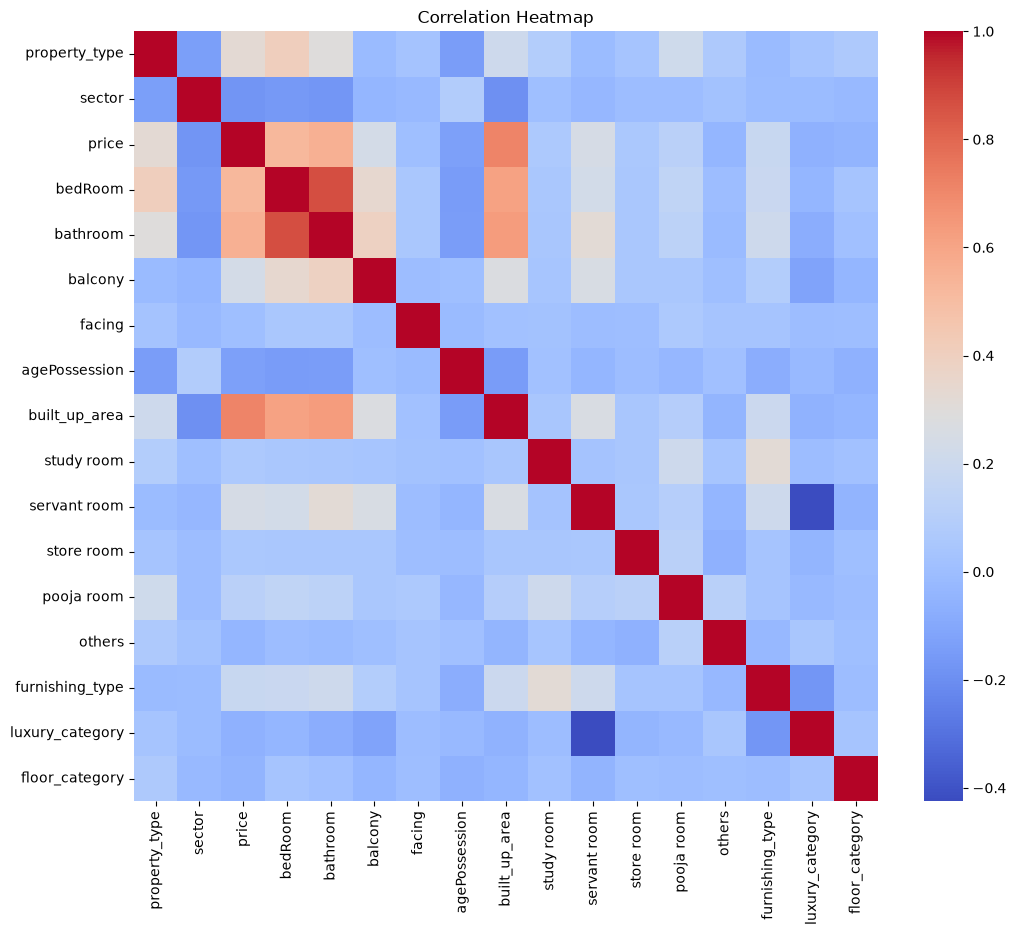

In [21]:
plt.figure(figsize=(12, 10))
sns.heatmap(data_label_encoded.corr(), cmap='coolwarm', annot=False)
plt.title('Correlation Heatmap')
plt.show()

In [22]:
fi_df1 = (
    data_label_encoded.corr()['price']
    .drop('price')
    .to_frame()
    .reset_index()
    .rename(columns={'index': 'feature', 'price': 'corr_coeff'})
)
fi_df1

,feature,corr_coeff
0,property_type,0.326252
1,sector,-0.175567
2,bedRoom,0.523319
3,bathroom,0.556142
4,balcony,0.234847
5,facing,0.003978
6,agePossession,-0.130124
7,built_up_area,0.713771
8,study room,0.060458
9,servant room,0.247309


## Technique 2 — Random Forest Feature Importance

In [23]:
from sklearn.ensemble import RandomForestRegressor

# Train a Random Forest regressor on label encoded data
rf_label = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_label.fit(X_label, y_label)

# Extract feature importance scores for label encoded data
fi_df2 = pd.DataFrame({
    'feature': X_label.columns,
    'rf_importance': rf_label.feature_importances_
}).sort_values(by='rf_importance', ascending=False)

fi_df2

,feature,rf_importance
7,built_up_area,0.600536
1,sector,0.198474
0,property_type,0.049961
3,bathroom,0.035570
2,bedRoom,0.023367
6,agePossession,0.016923
15,floor_category,0.015986
5,facing,0.013471
4,balcony,0.011589
13,furnishing_type,0.008924


## Technique 3 — Gradient Boosting Feature Importances

In [24]:
from sklearn.ensemble import GradientBoostingRegressor

# Train a Gradient Boosting regressor on label encoded data
gb_label = GradientBoostingRegressor(random_state=42)
gb_label.fit(X_label, y_label)

# Extract feature importance scores for label encoded data
fi_df3 = pd.DataFrame({
    'feature': X_label.columns,
    'gb_importance': gb_label.feature_importances_
}).sort_values(by='gb_importance', ascending=False)

fi_df3

,feature,gb_importance
7,built_up_area,0.708101
1,sector,0.139224
0,property_type,0.056197
3,bathroom,0.045562
2,bedRoom,0.018483
15,floor_category,0.008832
6,agePossession,0.006088
4,balcony,0.004865
5,facing,0.004422
9,servant room,0.004357


## Technique 4 — Permutation Importance

In [25]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

X_train_label, X_test_label, y_train_label, y_test_label = train_test_split(
    X_label, y_label, test_size=0.2, random_state=42
)

# Train a Random Forest regressor on label encoded training data
rf_perm = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_perm.fit(X_train_label, y_train_label)

# Calculate Permutation Importance
perm_importance = permutation_importance(
    rf_perm, X_test_label, y_test_label, n_repeats=30, random_state=42, n_jobs=-1
)

# Organize results into a DataFrame
fi_df4 = pd.DataFrame({
    'feature': X_label.columns,
    'permutation_importance': perm_importance.importances_mean
}).sort_values(by='permutation_importance', ascending=False)

fi_df4

,feature,permutation_importance
7,built_up_area,0.726356
1,sector,0.280311
0,property_type,0.096689
3,bathroom,0.043503
15,floor_category,0.026774
2,bedRoom,0.011636
4,balcony,0.007148
6,agePossession,0.004351
14,luxury_category,0.003619
13,furnishing_type,0.002589


## Technique 5 — LASSO Regression

In [26]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_label)

# Train a LASSO regression model
lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_scaled, y_label)

# Extract coefficients
fi_df5 = pd.DataFrame({
    'feature': X_label.columns,
    'lasso_coeff': lasso.coef_
}).sort_values(by='lasso_coeff', ascending=False)

fi_df5

,feature,lasso_coeff
7,built_up_area,1.737835
0,property_type,0.543490
3,bathroom,0.402309
9,servant room,0.126990
13,furnishing_type,0.096890
4,balcony,0.057260
10,store room,0.038264
11,pooja room,0.010162
8,study room,0.000000
14,luxury_category,0.000000


## Technique 6 — Recursive Feature Elimination (RFE)

In [27]:
from sklearn.feature_selection import RFE

# Initialize the base estimator
estimator = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# Apply RFE on the label-encoded training data
selector_label = RFE(estimator, n_features_to_select=X_label.shape[1], step=1)
selector_label = selector_label.fit(X_label, y_label)

# Get the selected features based on RFE
selected_features = X_label.columns[selector_label.support_]

# Extract the feature importances from the underlying Random Forest model
selected_coefficients = selector_label.estimator_.feature_importances_

# Organize the results into a DataFrame
fi_df6 = pd.DataFrame({
    'feature': selected_features,
    'rfe_score': selected_coefficients
}).sort_values(by='rfe_score', ascending=False)

fi_df6

,feature,rfe_score
7,built_up_area,0.600536
1,sector,0.198474
0,property_type,0.049961
3,bathroom,0.035570
2,bedRoom,0.023367
6,agePossession,0.016923
15,floor_category,0.015986
5,facing,0.013471
4,balcony,0.011589
13,furnishing_type,0.008924


## Technique 7 — Linear Regression Weights

In [28]:
from sklearn.linear_model import LinearRegression

# Train a linear regression model on the label-encoded and standardized training data
lin_reg = LinearRegression()
lin_reg.fit(X_scaled, y_label)

# Extract coefficients
fi_df7 = pd.DataFrame({
    'feature': X_label.columns,
    'reg_coeffs': lin_reg.coef_
}).sort_values(by='reg_coeffs', ascending=False)

fi_df7

,feature,reg_coeffs
7,built_up_area,1.747824
0,property_type,0.566847
3,bathroom,0.469692
9,servant room,0.131272
13,furnishing_type,0.106217
4,balcony,0.067085
10,store room,0.045860
11,pooja room,0.017823
14,luxury_category,0.008821
8,study room,0.003653


## Technique 8 — SHAP (TreeExplainer)

In [31]:
import shap

# Compute SHAP values using the trained Random Forest model
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_label, y_label)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_label)

# Mean absolute SHAP value per feature
shap_sum = np.abs(shap_values).mean(axis=0)
shap_values

C extension was not built during install!


ImportError: DLL load failed while importing _cext: An Application Control policy has blocked this file.